
# Ordinary Least Squares Estimation for the Contact-Tracing Model

**Objective.** This notebook implements a numerical Ordinary Least Squares (OLS) approach for estimating the tracing probability $p$ and the expected number of downstream contacts $m=E[K]$ in the contact-tracing model used by Maeva and inspired by Okolie, Müller and Kretzschmar.

We start with a small sample size $n=10 000$, as in Maeva's final numerical section, and we generate synthetic observations of

$$
T_{\mathrm{tot}} = \text{total number of detected individuals generated by one index case}.
$$

The important correction implemented here is that **full tracing includes both forward tracing and backward tracing**:

$$
T_{\mathrm{tot}} = T_{\mathrm{forward}} + B_{\mathrm{backward}}.
$$

Where:

- $T_{\mathrm{forward}}$: number of downstream infected contacts found by tracing;
- $B_{\mathrm{backward}}\in\{0,1\}$: indicator that the infector of the index case is also found.

The OLS estimator is obtained by minimizing the distance between empirical frequencies and theoretical probabilities:

$$
J_{\mathrm{OLS}}(p,m)
=\sum_i\left(\widehat f_i - \pi_i(p,m)\right)^2,
$$

where

$$
\widehat f_i = \frac{N_i}{n},\qquad
\pi_i(p,m)=P_{p,m}(T_{\mathrm{tot}}=i).
$$



## 1. Mathematical setting

We use the following parameters:

$$
\alpha=0.5,\qquad \beta=1.5,\qquad \sigma=0.5,
$$

and therefore

$$
\gamma=\alpha+\sigma.
$$

The true values used to generate the synthetic data are

$$
p_0=0.6,\qquad m_0=E[K]_0=4.
$$

The model ingredients are:

1. **Random degree**

$$
K\sim \mathrm{Poisson}(m).
$$

2. **Age since infection**

$$
a\sim \mathrm{Exponential}(\beta(m-1)).
$$

3. **Effective forward tracing probability**

$$
\widetilde p(a)
= p\frac{\beta}{\gamma-\beta}
\left(e^{-\beta a}-e^{-\gamma a}\right).
$$

4. **Forward tracing**

$$
T_{\mathrm{forward}}\mid a,K=k
\sim \mathrm{Binomial}(k,\widetilde p(a)).
$$

5. **Backward tracing correction**

The infector of the index case is still infectious with approximate probability

$$
P(I_a=1)=e^{-\gamma a}.
$$

It is then traced with probability $p$, hence

$$
B_{\mathrm{backward}}\mid a
\sim \mathrm{Bernoulli}\left(p e^{-\gamma a}\right).
$$

Finally,

$$
T_{\mathrm{tot}} = T_{\mathrm{forward}} + B_{\mathrm{backward}}.
$$


In [2]:
# 2. Imports and global configuration


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import gammaln
from scipy.optimize import minimize, differential_evolution, least_squares, dual_annealing
from numpy.polynomial.laguerre import laggauss

SEED = 123

# Epidemiological parameters fixed as in Maeva/Okolie simulation setting
ALPHA = 0.5
BETA = 1.5
SIGMA = 0.5
GAMMA = ALPHA + SIGMA

# True parameters used to generate synthetic data
P_TRUE = 0.6
M_TRUE = 4.0  

# Sample size requested by the user
N_SAMPLE = 10000

# Parameter bounds for numerical optimization
P_BOUNDS = (0.01, 0.99)
M_BOUNDS = (1.05, 10.0)  
BOUNDS = [P_BOUNDS, M_BOUNDS]

In [3]:
# 3. Model functions

def tracing_kernel(a, beta=BETA, gamma=GAMMA):
    
    a = np.asarray(a, dtype=float)
    return beta / (gamma - beta) * (np.exp(-beta * a) - np.exp(-gamma * a))


def p_tilde(a, p, beta=BETA, gamma=GAMMA):
    return np.clip(p * tracing_kernel(a, beta=beta, gamma=gamma), 0.0, 1.0)


def p_backward(a, p, gamma=GAMMA):
    return np.clip(p * np.exp(-gamma * np.asarray(a)), 0.0, 1.0)


def poisson_pmf(j, lam):
    lam = np.asarray(lam, dtype=float)
    if j < 0:
        return np.zeros_like(lam)
    with np.errstate(divide="ignore", invalid="ignore"):
        val = np.exp(-lam + j * np.log(lam) - gammaln(j + 1))
    if j == 0:
        val = np.where(lam == 0, 1.0, val)
    else:
        val = np.where(lam == 0, 0.0, val)
    return val


In [4]:
# 4. Synthetic data generation 

def simulate_contact_tracing_data(
    n,
    p,
    m,
    alpha=ALPHA,
    beta=BETA,
    sigma=SIGMA,
    seed=SEED,
    include_backward=True,
):
    gamma = alpha + sigma
    if m <= 1:
        raise ValueError("m = E[K] must be larger than 1.")

    rng = np.random.default_rng(seed)

    K = rng.poisson(lam=m, size=n)
    age_a = rng.exponential(scale=1.0 / (beta * (m - 1.0)), size=n)

    prob_forward = p_tilde(age_a, p=p, beta=beta, gamma=gamma)
    T_forward = rng.binomial(n=K, p=prob_forward)

    if include_backward:
        prob_backward = p_backward(age_a, p=p, gamma=gamma)
        B_backward = rng.binomial(n=1, p=prob_backward)
    else:
        prob_backward = np.zeros(n)
        B_backward = np.zeros(n, dtype=int)

    T_tot = T_forward + B_backward

    return pd.DataFrame({
        "K": K,
        "age_a": age_a,
        "prob_forward": prob_forward,
        "T_forward": T_forward,
        "prob_backward": prob_backward,
        "B_backward": B_backward,
        "T_tot": T_tot,
    })


synthetic_data = simulate_contact_tracing_data(
    n=N_SAMPLE,
    p=P_TRUE,
    m=M_TRUE,
    seed=SEED,
    include_backward=True,
)

synthetic_data.head()


,K,age_a,prob_forward,T_forward,prob_backward,B_backward,T_tot
0,2,0.065883,0.054610,0,0.561744,1,1
1,4,0.047133,0.039994,0,0.572376,1,1
2,5,0.049922,0.042213,1,0.570782,0,1
3,6,0.199536,0.139998,0,0.491466,1,1
4,3,0.004435,0.003970,0,0.597345,0,0


In [5]:

# Summary of the generated data
summary_counts = synthetic_data["T_tot"].value_counts().sort_index()
summary_table = pd.DataFrame({
    "T_tot": summary_counts.index,
    "Counts N_i": summary_counts.values,
    "Empirical frequency f_i": summary_counts.values / N_SAMPLE,
})

print("Total number of observations:", summary_counts.sum())
summary_table


Total number of observations: 10000


,T_tot,Counts N_i,Empirical frequency f_i
0,0,3093,0.3093
1,1,4689,0.4689
2,2,1637,0.1637
3,3,449,0.0449
4,4,109,0.0109
5,5,20,0.0020
6,6,2,0.0002
7,7,1,0.0001


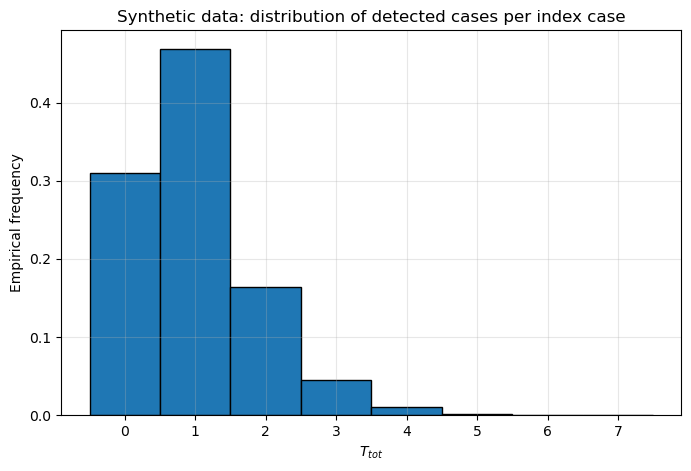

In [6]:

# Plot the histogram of the synthetic observations
plt.figure(figsize=(8, 5))
plt.hist(
    synthetic_data["T_tot"],
    bins=np.arange(synthetic_data["T_tot"].max() + 2) - 0.5,
    density=True,
    edgecolor="black",
)
plt.xlabel(r"$T_{tot}$")
plt.ylabel("Empirical frequency")
plt.title("Synthetic data: distribution of detected cases per index case")
plt.xticks(range(int(synthetic_data["T_tot"].max()) + 1))
plt.grid(alpha=0.3)

plt.savefig("Synthetic data (distribution of detected cases per index case).pdf",bbox_inches="tight")

plt.show()



## 5. Empirical frequencies for OLS

For OLS, the observed data are transformed into empirical frequencies:

$$
\widehat f_i = \frac{N_i}{n},
$$

where $N_i$ is the number of times we observe $T_{\mathrm{tot}}=i$.

In [8]:
# 6. Empirical distribution helper

def empirical_distribution(samples, L):
    samples = np.asarray(samples, dtype=int)
    counts = np.array([(samples == i).sum() for i in range(L + 1)], dtype=int)
    freq = counts / len(samples)
    tail_count = int((samples > L).sum())
    tail_freq = tail_count / len(samples)
    return counts, freq, tail_count, tail_freq

L = max(7, int(synthetic_data["T_tot"].max()))
i_values = np.arange(L + 1)

counts, f_empirical, tail_count, f_tail = empirical_distribution(synthetic_data["T_tot"].values, L=L)

frequency_table = pd.DataFrame({
    "i": i_values,
    "N_i": counts,
    "f_hat_i": f_empirical,
})

print(f"Chosen maximum explicit class L = {L}")

frequency_table


Chosen maximum explicit class L = 7


,i,N_i,f_hat_i
0,0,3093,0.3093
1,1,4689,0.4689
2,2,1637,0.1637
3,3,449,0.0449
4,4,109,0.0109
5,5,20,0.0020
6,6,2,0.0002
7,7,1,0.0001



## 6. Theoretical probabilities $\pi_i(p,m)$

Since

$$
K\sim \mathrm{Poisson}(m),
\qquad
T_{\mathrm{forward}}\mid a,K\sim \mathrm{Binomial}(K,\widetilde p(a)),
$$

we use the thinning property of the Poisson distribution:

$$
T_{\mathrm{forward}}\mid a
\sim \mathrm{Poisson}\left(m\widetilde p(a)\right).
$$

Let

$$
\lambda(a)=m\widetilde p(a).
$$

Then, with full tracing,

$$
\pi_i(p,m)=\int_0^\infty
\left[
pe^{-\gamma a}q_{i-1}(\lambda(a))+
\left(1-pe^{-\gamma a}\right)q_i(\lambda(a))
\right]
\beta(m-1)e^{-\beta(m-1)a}\,da,
$$

where

$$
q_j(\lambda)=e^{-\lambda}\frac{\lambda^j}{j!},
\qquad q_{-1}(\lambda)=0.
$$

For numerical stability, we evaluate this integral by **Gauss--Laguerre quadrature**. With the change of variable

$$
x=\beta(m-1)a,
$$

we have

$$
\pi_i(p,m)=\int_0^\infty e^{-x}G_i(x;p,m)\,dx.
$$


In [10]:
# 7. Theoretical probabilities by Gauss-Laguerre quadrature

_LAGUERRE_CACHE = {}

def get_laguerre_nodes(n_quad):
    if n_quad not in _LAGUERRE_CACHE:
        _LAGUERRE_CACHE[n_quad] = laggauss(n_quad)
    return _LAGUERRE_CACHE[n_quad]


def theoretical_probabilities(p, m, i_values, alpha=ALPHA, beta=BETA, sigma=SIGMA, n_quad=40):
    gamma = alpha + sigma

    if (p < 0) or (p > 1) or (m <= 1):
        return np.full(len(i_values), np.nan)

    x_nodes, w_nodes = get_laguerre_nodes(n_quad)
    a_nodes = x_nodes / (beta * (m - 1.0))

    prob_forward = p_tilde(a_nodes, p=p, beta=beta, gamma=gamma)
    lam = m * prob_forward
    prob_back = p_backward(a_nodes, p=p, gamma=gamma)

    pi_values = []
    for i in i_values:
        q_i = poisson_pmf(i, lam)
        q_i_minus_1 = poisson_pmf(i - 1, lam)

        integrand = prob_back * q_i_minus_1 + (1.0 - prob_back) * q_i
        pi_i = np.sum(w_nodes * integrand)
        pi_values.append(pi_i)

    return np.array(pi_values)


# Check probabilities at the true parameter values
pi_true = theoretical_probabilities(P_TRUE, M_TRUE, i_values)
pi_tail_true = max(0.0, 1.0 - pi_true.sum())

check_table = pd.DataFrame({
    "i": i_values,
    "f_hat_i": f_empirical,
    "pi_i(true p, true m)": pi_true,
})



## 7. OLS objective function

The objective function is

$$
J_{\mathrm{OLS}}(p,m)=\sum_{i=0}^{L}\left(\widehat f_i-\pi_i(p,m)\right)^2.
$$



In [12]:
# 8. OLS residual vector and objective

def residual_vector(theta, weighted=False, eps=1e-8):
    p, m = theta

    # Penalize invalid values. This is useful for algorithms that test outside bounds.
    if not (P_BOUNDS[0] <= p <= P_BOUNDS[1]) or not (M_BOUNDS[0] <= m <= M_BOUNDS[1]):
        return np.ones(len(i_values) + 1) * 1e3

    pi = theoretical_probabilities(p, m, i_values)

    if not np.all(np.isfinite(pi)):
        return np.ones(len(i_values) + 1) * 1e3

    pi_tail = max(0.0, 1.0 - pi.sum())

    empirical = np.r_[f_empirical, f_tail]
    theoretical = np.r_[pi, pi_tail]

    resid = empirical - theoretical

    if weighted:
        # Optional weighted version, not used as the main objective.
        resid = resid / np.sqrt(theoretical + eps)

    return resid


def J_OLS(theta):
    r = residual_vector(theta, weighted=False)
    return float(np.sum(r**2))


def J_WLS(theta):
    r = residual_vector(theta, weighted=True)
    return float(np.sum(r**2))


print("J_OLS at true parameters:", J_OLS([P_TRUE, M_TRUE]))
print("J_OLS at a deliberately wrong parameter pair (p=0.2,m=8):", J_OLS([0.2, 8.0]))


J_OLS at true parameters: 5.466766139366217e-06
J_OLS at a deliberately wrong parameter pair (p=0.2,m=8): 0.19935340476349014



## 8. Optimization algorithms

We now minimize $J_{\mathrm{OLS}}(p,m)$ using several numerical methods:

1. Coarse grid search;
2. L-BFGS-B;
3. Powell;
4. Nelder-Mead;
5. Nonlinear least-squares using `scipy.optimize.least_squares`;
6. Differential Evolution;
7. Dual Annealing;
8. A simple projected finite-difference gradient descent.

The goal is not only to get one estimate, but also to check whether different algorithms lead to similar minima.


In [17]:
# 9. Coarse grid search

p_grid = np.linspace(P_BOUNDS[0], P_BOUNDS[1], 35)
m_grid = np.linspace(M_BOUNDS[0], M_BOUNDS[1], 35)

J_grid = np.empty((len(m_grid), len(p_grid)))

for im, m_val in enumerate(m_grid):
    for ip, p_val in enumerate(p_grid):
        J_grid[im, ip] = J_OLS([p_val, m_val])

best_index = np.unravel_index(np.argmin(J_grid), J_grid.shape)
initial_from_grid = np.array([p_grid[best_index[1]], m_grid[best_index[0]]])

print("Best grid estimate:")
print(f"p = {initial_from_grid[0]:.4f}, m = {initial_from_grid[1]:.4f}, J = {J_grid[best_index]:.6g}")


Best grid estimate:
p = 0.5865, m = 4.7353, J = 1.018e-05


In [18]:
# 10. Local optimization algorithms

optimization_results = []

def add_result(method_name, theta, objective_value, success=True, message=""):
    optimization_results.append({
        "method": method_name,
        "p_hat": float(theta[0]),
        "m_hat_EK": float(theta[1]),
        "J_OLS": float(objective_value),
        "success": bool(success),
        "message": str(message),
    })

# 1. Grid search result
add_result("Coarse grid search", initial_from_grid, J_OLS(initial_from_grid), True, "coarse grid")

# 2. L-BFGS-B from grid initialization
res_lbfgs = minimize(
    J_OLS,
    x0=initial_from_grid,
    method="L-BFGS-B",
    bounds=BOUNDS,
    options={"maxiter": 500, "ftol": 1e-12},
)
add_result("L-BFGS-B", res_lbfgs.x, res_lbfgs.fun, res_lbfgs.success, res_lbfgs.message)

# 3. Powell from grid initialization
res_powell = minimize(
    J_OLS,
    x0=initial_from_grid,
    method="Powell",
    bounds=BOUNDS,
    options={"maxiter": 500, "xtol": 1e-10, "ftol": 1e-12},
)
add_result("Powell", res_powell.x, res_powell.fun, res_powell.success, res_powell.message)

# 4. Nelder-Mead with bounds
res_nm = minimize(
    J_OLS,
    x0=initial_from_grid,
    method="Nelder-Mead",
    bounds=BOUNDS,
    options={"maxiter": 800, "xatol": 1e-10, "fatol": 1e-12},
)
add_result("Nelder-Mead", res_nm.x, res_nm.fun, res_nm.success, res_nm.message)

# 5. Nonlinear least squares directly on the residual vector
res_ls = least_squares(
    residual_vector,
    x0=initial_from_grid,
    bounds=([P_BOUNDS[0], M_BOUNDS[0]], [P_BOUNDS[1], M_BOUNDS[1]]),
    xtol=1e-12,
    ftol=1e-12,
    gtol=1e-12,
    max_nfev=1000,
)
add_result("least_squares", res_ls.x, np.sum(res_ls.fun**2), res_ls.success, res_ls.message)

pd.DataFrame(optimization_results)


,method,p_hat,m_hat_EK,J_OLS,success,message
0,Coarse grid search,0.586471,4.735294,0.000010,True,coarse grid
1,L-BFGS-B,0.599357,4.105492,0.000001,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
2,Powell,0.599356,4.105551,0.000001,True,Optimization terminated successfully.
3,Nelder-Mead,0.599356,4.105551,0.000001,True,Optimization terminated successfully.
4,least_squares,0.599356,4.105551,0.000001,True,`ftol` termination condition is satisfied.


In [19]:
# 11. Global optimization algorithms

# Differential Evolution
res_de = differential_evolution(
    J_OLS,
    bounds=BOUNDS,
    seed=SEED,
    tol=1e-8,
    maxiter=35,
    popsize=8,
    polish=True,
    updating="immediate",
    workers=1,
)
add_result("Differential Evolution", res_de.x, res_de.fun, res_de.success, res_de.message)

# Dual Annealing
res_da = dual_annealing(
    J_OLS,
    bounds=BOUNDS,
    seed=SEED,
    maxiter=15,
    no_local_search=True,
    x0=initial_from_grid,
)
add_result("Dual Annealing", res_da.x, res_da.fun, True, res_da.message)

pd.DataFrame(optimization_results)


,method,p_hat,m_hat_EK,J_OLS,success,message
0,Coarse grid search,0.586471,4.735294,0.000010,True,coarse grid
1,L-BFGS-B,0.599357,4.105492,0.000001,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
2,Powell,0.599356,4.105551,0.000001,True,Optimization terminated successfully.
3,Nelder-Mead,0.599356,4.105551,0.000001,True,Optimization terminated successfully.
4,least_squares,0.599356,4.105551,0.000001,True,`ftol` termination condition is satisfied.
5,Differential Evolution,0.599358,4.105526,0.000001,False,Maximum number of iterations has been exceeded.
6,Dual Annealing,0.586471,4.735294,0.000010,True,['Maximum number of iteration reached']


In [16]:
# 12. Custom projected finite-difference gradient descent

def finite_difference_gradient(fun, theta, h=1e-5):
    """Central finite-difference gradient for a two-dimensional parameter vector."""
    theta = np.asarray(theta, dtype=float)
    grad = np.zeros_like(theta)
    for j in range(len(theta)):
        step = np.zeros_like(theta)
        step[j] = h
        grad[j] = (fun(theta + step) - fun(theta - step)) / (2 * h)
    return grad


def projected_gradient_descent(
    fun,
    x0,
    bounds,
    learning_rate=0.5,
    max_iter=120,
    tol=1e-10,
):

    x = np.asarray(x0, dtype=float)
    history = []
    low = np.array([b[0] for b in bounds])
    high = np.array([b[1] for b in bounds])

    current_value = fun(x)

    for it in range(max_iter):
        grad = finite_difference_gradient(fun, x)
        step = learning_rate
        improved = False

        # Backtracking line search
        for _ in range(20):
            candidate = np.clip(x - step * grad, low, high)
            candidate_value = fun(candidate)
            if candidate_value <= current_value:
                improved = True
                break
            step *= 0.5

        history.append((it, x[0], x[1], current_value, np.linalg.norm(grad)))

        if not improved:
            break

        if abs(current_value - candidate_value) < tol:
            x = candidate
            current_value = candidate_value
            break

        x = candidate
        current_value = candidate_value

    history_df = pd.DataFrame(history, columns=["iteration", "p", "m_EK", "J_OLS", "grad_norm"])
    return x, current_value, history_df

pgd_x, pgd_val, pgd_history = projected_gradient_descent(
    J_OLS,
    x0=initial_from_grid,
    bounds=BOUNDS,
    learning_rate=0.5,
    max_iter=120,
)

add_result("Projected finite-diff GD", pgd_x, pgd_val, True, "pedagogical custom optimizer")

print("Projected gradient descent estimate:")
print(f"p_hat = {pgd_x[0]:.6f}, m_hat = {pgd_x[1]:.6f}, J = {pgd_val:.6g}")
pgd_history.tail()


Projected gradient descent estimate:
p_hat = 0.586192, m_hat = 4.733801, J = 1.00669e-05


,iteration,p,m_EK,J_OLS,grad_norm
115,115,0.586191,4.733863,0.00001,0.000025
116,116,0.586191,4.733851,0.00001,0.000025
117,117,0.586191,4.733838,0.00001,0.000025
118,118,0.586192,4.733826,0.00001,0.000025
119,119,0.586192,4.733814,0.00001,0.000025


In [20]:
# 13. Compare optimization results

results_df = pd.DataFrame(optimization_results)
results_df["abs_error_p"] = np.abs(results_df["p_hat"] - P_TRUE)
results_df["abs_error_m"] = np.abs(results_df["m_hat_EK"] - M_TRUE)
results_df["squared_error_total"] = (results_df["p_hat"] - P_TRUE)**2 + (results_df["m_hat_EK"] - M_TRUE)**2
results_df = results_df.sort_values("J_OLS").reset_index(drop=True)

best_row = results_df.iloc[0]
P_OLS = float(best_row["p_hat"])
M_OLS = float(best_row["m_hat_EK"])

print("Best OLS estimate found:")
print(f"p_hat_OLS = {P_OLS:.6f}")
print(f"E[K]_hat_OLS = {M_OLS:.6f}")
print(f"J_OLS = {best_row['J_OLS']:.6g}")
print("\nTrue parameters:")
print(f"p_true = {P_TRUE}, E[K]_true = {M_TRUE}")

results_df


Best OLS estimate found:
p_hat_OLS = 0.599356
E[K]_hat_OLS = 4.105551
J_OLS = 1.34827e-06

True parameters:
p_true = 0.6, E[K]_true = 4.0


,method,p_hat,m_hat_EK,J_OLS,success,message,abs_error_p,abs_error_m,squared_error_total
0,Powell,0.599356,4.105551,0.000001,True,Optimization terminated successfully.,0.000644,0.105551,0.011141
1,Nelder-Mead,0.599356,4.105551,0.000001,True,Optimization terminated successfully.,0.000644,0.105551,0.011141
2,least_squares,0.599356,4.105551,0.000001,True,`ftol` termination condition is satisfied.,0.000644,0.105551,0.011141
3,L-BFGS-B,0.599357,4.105492,0.000001,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,0.000643,0.105492,0.011129
4,Differential Evolution,0.599358,4.105526,0.000001,False,Maximum number of iterations has been exceeded.,0.000642,0.105526,0.011136
5,Coarse grid search,0.586471,4.735294,0.000010,True,coarse grid,0.013529,0.735294,0.540840
6,Dual Annealing,0.586471,4.735294,0.000010,True,['Maximum number of iteration reached'],0.013529,0.735294,0.540840


In [21]:

# ============================================================
# 14. Empirical vs fitted theoretical distribution
# ============================================================

pi_ols = theoretical_probabilities(P_OLS, M_OLS, i_values)
pi_tail_ols = max(0.0, 1.0 - pi_ols.sum())

comparison_df = pd.DataFrame({
    "i": i_values,
    "empirical_frequency": f_empirical,
    "theory_at_true_parameters": pi_true,
    "theory_at_OLS_estimate": pi_ols,
})

comparison_df


,i,empirical_frequency,theory_at_true_parameters,theory_at_OLS_estimate
0,0,0.3093,0.310996,0.309215
1,1,0.4689,0.469175,0.469258
2,2,0.1637,0.162258,0.162933
3,3,0.0449,0.044958,0.045584
4,4,0.0109,0.010257,0.010541
5,5,0.0020,0.001974,0.002062
6,6,0.0002,0.000327,0.000348
7,7,0.0001,0.000048,0.000052


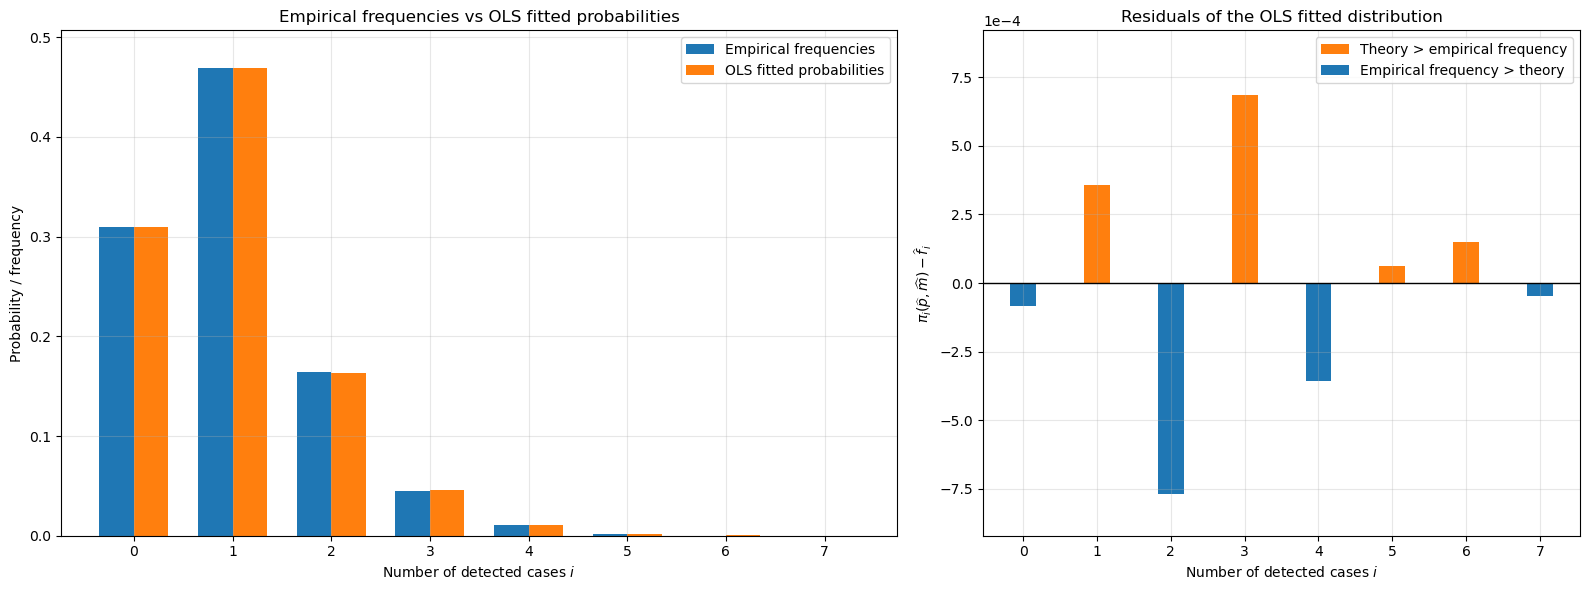

Figure saved as: figures\empirical_vs_OLS_fitted_distribution_colored_residuals.pdf


In [22]:
# Empirical distribution vs OLS fitted distribution
# Residual colors according to interpretation

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Folder where the figure will be saved
fig_dir = "figures"
os.makedirs(fig_dir, exist_ok=True)

pdf_path = os.path.join(fig_dir, "empirical_vs_OLS_fitted_distribution_colored_residuals.pdf")

# X-axis positions
x = np.arange(len(i_values))
width = 0.35

# Colors
empirical_color = "tab:blue"
theory_color = "tab:orange"

# Residuals: OLS theory - empirical
res_ols = pi_ols - f_empirical

# Color rule for residuals
# Positive residual: theory > empirical
# Negative residual: empirical > theory
res_colors = [
    theory_color if r >= 0 else empirical_color
    for r in res_ols
]

# Useful limit for residual plot
max_abs_res = np.max(np.abs(res_ols))
ylim_res = 1.20 * max_abs_res if max_abs_res > 0 else 1e-6

# Create figure with two panels
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(16, 6),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

# Panel 1: empirical distribution and OLS fitted distribution

ax1.bar(
    x - width / 2,
    f_empirical,
    width=width,
    color=empirical_color,
    label="Empirical frequencies"
)

ax1.bar(
    x + width / 2,
    pi_ols,
    width=width,
    color=theory_color,
    label="OLS fitted probabilities"
)

ax1.set_xlabel(r"Number of detected cases $i$")
ax1.set_ylabel("Probability / frequency")
ax1.set_title("Empirical frequencies vs OLS fitted probabilities")
ax1.set_xticks(x)
ax1.set_xticklabels(i_values)

ymax = max(np.max(f_empirical), np.max(pi_ols))
ax1.set_ylim(0, 1.08 * ymax)

ax1.legend()
ax1.grid(alpha=0.3)

# Panel 2: residuals with sign-based colors

ax2.axhline(0, color="black", linewidth=1)

ax2.bar(
    x,
    res_ols,
    width=width,
    color=res_colors
)

ax2.set_xlabel(r"Number of detected cases $i$")
ax2.set_ylabel(r"$\pi_i(\widehat p,\widehat m)-\widehat f_i$")
ax2.set_title("Residuals of the OLS fitted distribution")
ax2.set_xticks(x)
ax2.set_xticklabels(i_values)
ax2.set_ylim(-ylim_res, ylim_res)
ax2.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))

# Custom legend for interpretation
legend_elements = [
    Patch(facecolor=theory_color, label="Theory > empirical frequency"),
    Patch(facecolor=empirical_color, label="Empirical frequency > theory")
]

ax2.legend(handles=legend_elements)
ax2.grid(alpha=0.3)

plt.tight_layout()

# Save as PDF
plt.savefig("Empirical frequencies vs OLS fitted probabilities.pdf",bbox_inches="tight")
#plt.savefig(pdf_path, format="pdf", bbox_inches="tight")

plt.show()

print(f"Figure saved as: {pdf_path}")

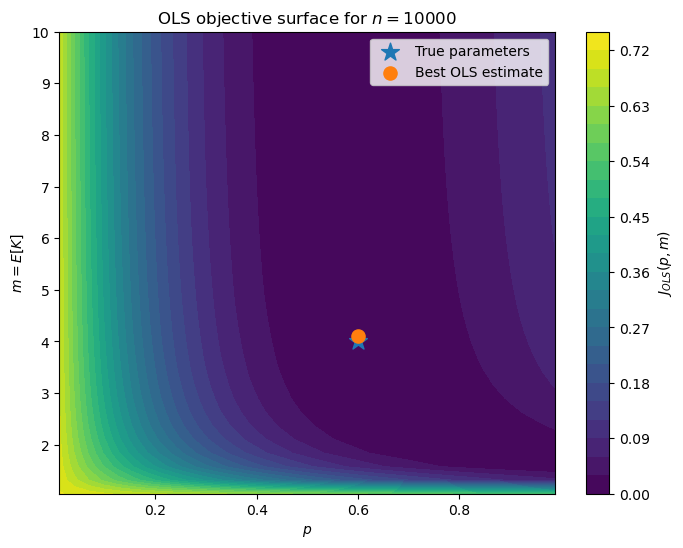

In [23]:
# 15. Objective surface visualization

plt.figure(figsize=(8, 6))
P_mesh, M_mesh = np.meshgrid(p_grid, m_grid)
levels = 25
cont = plt.contourf(P_mesh, M_mesh, J_grid, levels=levels)
plt.colorbar(cont, label=r"$J_{OLS}(p,m)$")
plt.scatter([P_TRUE], [M_TRUE], marker="*", s=180, label="True parameters")
plt.scatter([P_OLS], [M_OLS], marker="o", s=90, label="Best OLS estimate")
plt.xlabel(r"$p$")
plt.ylabel(r"$m=E[K]$")
plt.title(r"OLS objective surface for $n=10000$")
plt.legend()

plt.savefig("OLS objective surface.pdf",bbox_inches="tight")
plt.show()



## 10. Optional: sensitivity with different sample sizes

This cell is optional. It repeats the same experiment for different sample sizes. It can be useful for the chapter discussion, because it shows how the OLS method behaves when the number of observations increases.

Set `RUN_SENSITIVITY = True` to execute it.


In [24]:

# ============================================================
# 16. Optional sensitivity analysis
# ============================================================

RUN_SENSITIVITY = True

if RUN_SENSITIVITY:
    sensitivity_rows = []
    for n_test in [100, 1000, 10000, 100000, 1000000]:
        data_test = simulate_contact_tracing_data(
            n=n_test,
            p=P_TRUE,
            m=M_TRUE,
            seed=SEED,
            include_backward=True,
        )
        samples_test = data_test["T_tot"].values
        L_test = max(10, int(samples_test.max()))
        i_values_test = np.arange(L_test + 1)
        counts_test, freq_test, tail_count_test, tail_freq_test = empirical_distribution(samples_test, L=L_test)

        # Local objective using the current sample size
        def residual_test(theta):
            p, m = theta
            if not (P_BOUNDS[0] <= p <= P_BOUNDS[1]) or not (M_BOUNDS[0] <= m <= M_BOUNDS[1]):
                return np.ones(len(i_values_test) + 1) * 1e3
            pi = theoretical_probabilities(p, m, i_values_test)
            pi_tail = max(0.0, 1.0 - pi.sum())
            return np.r_[freq_test - pi, tail_freq_test - pi_tail]

        def obj_test(theta):
            r = residual_test(theta)
            return float(np.sum(r**2))

        de_test = differential_evolution(
            obj_test,
            bounds=BOUNDS,
            seed=SEED,
            tol=1e-7,
            maxiter=60,
            popsize=10,
            polish=True,
        )

        sensitivity_rows.append({
            "n": n_test,
            "p_hat_OLS": de_test.x[0],
            "m_hat_EK_OLS": de_test.x[1],
            "J_OLS": de_test.fun,
            "max_observed_Ttot": int(samples_test.max()),
        })

    sensitivity_df = pd.DataFrame(sensitivity_rows)
    display(sensitivity_df)


,n,p_hat_OLS,m_hat_EK_OLS,J_OLS,max_observed_Ttot
0,100,0.681240,2.401931,2.505891e-03,4
1,1000,0.920029,1.734432,2.442878e-04,5
2,10000,0.599356,4.105551,1.348261e-06,7
3,100000,0.585727,4.496212,2.982248e-06,7
4,1000000,0.598856,4.024601,2.384030e-07,8
